In [15]:
import getpass
import json
import os
import sqlite3
import subprocess
from datetime import UTC, datetime, timedelta
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from skyfield.api import EarthSatellite, load, wgs84
from tqdm.notebook import tqdm

In [16]:
# Helper functions


def get_omm_snapshot(snapshot_id):
    conn = sqlite3.connect("satcap.db")
    conn.row_factory = sqlite3.Row
    conn.execute("PRAGMA foreign_keys = ON")
    omm_snapshot = conn.execute("SELECT * FROM omm_snapshots WHERE id = ?", (snapshot_id,)).fetchone()
    columns = conn.execute("PRAGMA table_info(omm_snapshots)").fetchall()
    column_names = [col[1] for col in columns]
    omm = list(zip(column_names, list(omm_snapshot), strict=True))
    conn.close()
    return omm


def parse_utc_time(value):
    """Convert an ISO-8601 timestamp or UNIX timestamp to a UTC datetime."""
    if isinstance(value, (int, float)):
        return datetime.fromtimestamp(value, tz=UTC)

    dt = datetime.fromisoformat(value.replace("Z", "+00:00"))

    dt = dt.replace(tzinfo=UTC) if dt.tzinfo is None else dt.astimezone(UTC)

    return dt


def satellite_from_omm(omm):
    """
    Construct a Skyfield EarthSatellite from OMM orbital elements.

    `omm` can be either:
        - a dict
        - a list of (key, value) tuples
    """
    if not isinstance(omm, dict):
        omm = dict(omm)

    ts = load.timescale()

    # OMM epoch is UTC and has no timezone suffix in your data.
    datetime.fromisoformat(omm["epoch"]).replace(tzinfo=UTC)

    # Skyfield's EarthSatellite constructor expects TLE lines, so construct
    # the satellite directly from the OMM elements using the SGP4 model.
    sat = EarthSatellite(
        omm["tle_line1"],
        omm["tle_line2"],
        omm["object_name"],
        ts,
    )

    return sat, ts


def doppler_track(
    metadata,
    omm,
    station_lat,
    station_lon,
    station_alt_m=0.0,
    rate_hz=10.0,
):
    """
    Generate a Doppler time/frequency series for a satellite pass.

    Returns a pandas DataFrame with:
        time        UTC datetime
        unix_time   UNIX timestamp
        range_km    satellite range from station
        range_rate_m_s  radial velocity
        doppler_hz  Doppler offset from nominal center frequency
    """

    # Normalize OMM
    if not isinstance(omm, dict):
        omm = dict(omm)

    # ------------------------------------------------------------------
    # Input metadata
    # ------------------------------------------------------------------

    aos = parse_utc_time(metadata["aos"])
    los = parse_utc_time(metadata["los"])
    f_nom = float(metadata["f_center"])

    # ------------------------------------------------------------------
    # Satellite
    # ------------------------------------------------------------------

    sat, ts = satellite_from_omm(omm)

    # Ground station
    site = wgs84.latlon(
        station_lat,
        station_lon,
        elevation_m=station_alt_m,
    )

    # ------------------------------------------------------------------
    # Time vector
    # ------------------------------------------------------------------

    duration = (los - aos).total_seconds()

    n_samples = round(duration * rate_hz) + 1

    times = [aos + timedelta(seconds=i / rate_hz) for i in range(n_samples)]

    t_sf = ts.from_datetimes(times)

    # ------------------------------------------------------------------
    # Relative satellite state
    # ------------------------------------------------------------------

    rel = (sat - site).at(t_sf)

    r_km = np.asarray(rel.position.km)
    v_km_s = np.asarray(rel.velocity.km_per_s)

    # r and v have shape (3, N)
    r_norm = np.linalg.norm(r_km, axis=0)

    dot_rv = np.einsum("ij,ij->j", r_km, v_km_s)

    # Positive = satellite moving away from station
    range_rate_km_s = dot_rv / r_norm
    range_rate_m_s = range_rate_km_s * 1000.0

    # ------------------------------------------------------------------
    # Doppler
    # ------------------------------------------------------------------

    c = 299_792_458.0

    # Same convention as your original script:
    #
    # approaching  -> positive Doppler
    # receding     -> negative Doppler
    #
    doppler_hz = -(range_rate_m_s / c) * f_nom

    # ------------------------------------------------------------------
    # Output
    # ------------------------------------------------------------------

    unix_time = np.array([t.timestamp() for t in times])

    df = pd.DataFrame(
        {
            "time": times,
            "unix_time": unix_time,
            "range_km": r_norm,
            "range_rate_m_s": range_rate_m_s,
            "doppler_hz": doppler_hz,
        }
    )

    return df


def pass_alt_az(
    metadata,
    omm,
    station_lat,
    station_lon,
    station_alt_m=0.0,
):
    """
    Generate azimuth/elevation for every second of a satellite pass.

    Returns a pandas DataFrame with:
        time        UTC datetime
        unix_time   UNIX timestamp
        elapsed_s   seconds from AOS
        az_deg      azimuth in degrees [0, 360)
        alt_deg     elevation in degrees [-90, 90]
    """

    # Normalize OMM
    if not isinstance(omm, dict):
        omm = dict(omm)

    # ------------------------------------------------------------------
    # Input metadata
    # ------------------------------------------------------------------

    aos = parse_utc_time(metadata["aos"])
    los = parse_utc_time(metadata["los"])

    # ------------------------------------------------------------------
    # Satellite
    # ------------------------------------------------------------------

    sat, ts = satellite_from_omm(omm)

    # Ground station
    site = wgs84.latlon(
        station_lat,
        station_lon,
        elevation_m=station_alt_m,
    )

    # ------------------------------------------------------------------
    # Time vector: one sample every second from AOS through LOS
    # ------------------------------------------------------------------

    duration = (los - aos).total_seconds()

    n_samples = int(np.floor(duration)) + 1

    elapsed_s = np.arange(n_samples, dtype=float)

    times = [aos + timedelta(seconds=float(t)) for t in elapsed_s]

    t_sf = ts.from_datetimes(times)

    # ------------------------------------------------------------------
    # Altitude / azimuth
    # ------------------------------------------------------------------

    difference = sat - site
    topocentric = difference.at(t_sf)

    alt, az, distance = topocentric.altaz()

    alt_deg = np.asarray(alt.degrees)
    az_deg = np.asarray(az.degrees)
    range_km = np.asarray(distance.km)

    # ------------------------------------------------------------------
    # Output
    # ------------------------------------------------------------------

    unix_time = np.array([t.timestamp() for t in times])

    df = pd.DataFrame(
        {
            "time": times,
            "unix_time": unix_time,
            "elapsed_s": elapsed_s,
            "az_deg": az_deg,
            "alt_deg": alt_deg,
            "range_km": range_km,
        }
    )

    return df


def measure_iq_power(
    target_observation,
    track,
    gr_script="gr_power_estimator.py",
    iq_pattern="*.iq",
    input_sample_rate=150_000,
    averaging_samples=15_000,
    frequency_offset=2_180.0,
    doppler_filename="doppler_track.txt",
    username=None,
):
    target_observation = Path(target_observation).expanduser().resolve()
    gr_script = Path(gr_script).expanduser().resolve()

    if username is None:
        username = getpass.getuser()

    # ------------------------------------------------------------
    # Validate inputs
    # ------------------------------------------------------------

    if not target_observation.exists():
        raise FileNotFoundError(f"Observation directory does not exist: {target_observation}")

    if not gr_script.exists():
        raise FileNotFoundError(f"GNU Radio script does not exist: {gr_script}")

    required_columns = {"unix_time", "doppler_hz"}

    missing = required_columns - set(track.columns)

    if missing:
        raise ValueError(f"Doppler track is missing columns: {missing}")

    # ------------------------------------------------------------
    # 1. Generate Doppler correction file
    # ------------------------------------------------------------

    doppler_path = target_observation / doppler_filename

    track[["unix_time", "doppler_hz"]].to_csv(
        doppler_path,
        sep=" ",
        header=False,
        index=False,
        float_format="%.6f",
    )

    # print(f"Doppler track: {doppler_path}")

    # ------------------------------------------------------------
    # 2. Find IQ files
    # ------------------------------------------------------------

    iq_files = sorted(target_observation.glob(iq_pattern))

    if not iq_files:
        raise FileNotFoundError(f"No IQ files matching {iq_pattern!r} found in {target_observation}")

    #
    #
    # (f"Found {len(iq_files)} IQ file(s)")

    # ------------------------------------------------------------
    # Results
    # ------------------------------------------------------------

    results = {}

    # ------------------------------------------------------------
    # 3. Process each IQ file
    # ------------------------------------------------------------

    for iq_path in iq_files:
        # Use a separate output file for each IQ file.
        #
        # This is important if target_observation contains multiple
        # recordings.
        output_path = iq_path.with_name(f"{iq_path.stem}_power.csv")

        # --------------------------------------------------------
        # RadioConda activation
        #
        # Equivalent to:
        #
        # eval "$(/Users/{uname}/radioconda/bin/conda shell.zsh hook)"
        #
        # followed by running gr_script.py.
        # --------------------------------------------------------

        # arm gnuradio installation:
        # conda_path = f"/Users/{username}/radioconda/bin/conda"
        # activate_env_command = f"eval \"$({conda_path} shell.zsh hook)\""
        # x86_64 gnuradio installation:
        activate_env_command = f"source /Users/{username}/radioconda/bin/activate"
        command = f"""
{activate_env_command}
python3 "{gr_script}" \
    --iq "{iq_path}" \
    --doppler "{doppler_path}" \
    --sample-rate {input_sample_rate} \
    --scale {averaging_samples} \
    --freq-offset {frequency_offset} \
    --output "{output_path}"
"""

        completed = subprocess.run(
            ["zsh", "-lc", command],
            cwd=str(gr_script.parent),
            text=True,
            capture_output=True,
        )

        # --------------------------------------------------------
        # Show GNU Radio output
        # --------------------------------------------------------

        if completed.stdout:
            pass

        if completed.returncode != 0:
            raise RuntimeError(
                "GNU Radio script failed.\n"
                f"Return code: {completed.returncode}\n"
                f"IQ file: {iq_path}\n"
                f"Command:\n{command}"
            )

        # --------------------------------------------------------
        # 4. Read resulting CSV
        # --------------------------------------------------------

        if not output_path.exists():
            raise FileNotFoundError(
                f"GNU Radio completed successfully but did not produce the expected CSV:\n{output_path}"
            )

        df = pd.read_csv(output_path)

        df["observation"] = target_observation.name

        results[str(iq_path)] = df

    return results


def polar_plot(*dfs, name="", color_range=(-30, 0)):
    fig = plt.figure(figsize=(16, 16))
    ax = plt.subplot(111, polar=True)

    for df in dfs:
        # Convert elevation to radial distance
        alts = 90 - df["alt_deg"].to_numpy()
        azs = np.radians(df["az_deg"].to_numpy())
        power = df["power_db"].to_numpy()

        ax.scatter(
            azs,
            alts,
            c=power,
            cmap="turbo",
            vmin=color_range[0],
            vmax=color_range[1],
            s=10,
        )

    ax.set_theta_zero_location("N")
    ax.set_xlim(0, 2 * np.pi)
    ax.set_ylim(0, 90)

    ax.set_yticks(range(0, 91, 30))
    ax.set_yticklabels(range(90, -1, -30))

    ax.set_xticks(np.radians(range(0, 360, 30)))

    ax.set_title(name)

    # cbar = fig.colorbar(scatter, ax=ax, pad=0.1)
    # cbar.set_label("Power (dB)")

    return fig

In [17]:
def process_observations(target_id):
    dataframes = []

    observations = Path("/Users/tedvtorov/Desktop/ROSARP-OBS")
    for target_observation in tqdm(observations.iterdir()):
        if not target_observation.is_dir():
            continue
        with open(target_observation / "metadata.json") as f:
            metadata = json.load(f)
            if metadata["norad_id"] != target_id:
                continue

        # Rule out ionosphere induced effects
        # 1) Find a .json.zip file in the observation folder
        # json_zip_file = next(iter(target_observation.glob("*.json.zip")), None)
        # with ZipFile(json_zip_file, "r") as z:
        #     names = sorted(
        #         [n for n in z.namelist() if n.lower().endswith(".json") and not n.endswith("/")],
        #         key=lambda n: (n.count("/"), len(n), n.lower()),
        #     )
        #     ionospheredata = json.loads(z.read(names[0]).decode("utf-8-sig"))
        # kps = ionospheredata["geomagnetic_conditions"]["gfz_kp"]
        # if not kps:
        #     print(f"Skipping {target_observation} due to missing geomagnetic data")
        #     continue
        # kp_latest_timestamp = 0
        # kp_current = 0
        # for kp in kps:
        #     if kp[0] > kp_latest_timestamp:
        #         kp_latest_timestamp = kp[0]
        #         kp_current = kp[1]
        # if kp_current > 3:
        #     print(f"Skipping {target_observation} due to high geomagnetic activity (Kp={kp_current})")
        #     continue

        satellite_specific_offsets = {
            57166: 2180.0,
            59051: 2980.0,
        }

        omm = get_omm_snapshot(metadata["omm_snapshot_id"])
        track = doppler_track(
            metadata,
            omm,
            station_lat=55.5269,
            station_lon=37.0888,
            station_alt_m=127.0,
            rate_hz=10.0,
        )
        results = measure_iq_power(
            target_observation=target_observation,
            track=track,
            gr_script="./gnuradio_scripts/gr_power_estimator.py",
            frequency_offset=satellite_specific_offsets.get(metadata["norad_id"], 2180.0),
        )

        df_altaz = pass_alt_az(
            metadata,
            omm,
            station_lat=55.5269,
            station_lon=37.0888,
            station_alt_m=127.0,
        )
        power_df = results[next(iter(results))]

        power_df["_second"] = np.floor(power_df["time_s"]).astype(int)

        power_altaz_df = df_altaz.merge(
            power_df,
            left_on="elapsed_s",
            right_on="_second",
            how="inner",
        )

        power_altaz_df = power_altaz_df.drop(
            columns=["elapsed_s", "_second"],
        )

        dataframes.append(power_altaz_df)
    polar_plot(*dataframes)
    plt.show()
    return dataframes

In [18]:
# # temp: find observations with high scintillation
# from pathlib import Path
# import json

# observations_root = Path("~/Desktop/ROSARP-OBS").expanduser().resolve()

# for observation in sorted(observations_root.iterdir()):
#     if not observation.is_dir():
#         continue

#     metadata_path = observation / "metadata.json"
#     if not metadata_path.exists():
#         continue

#     metadata = json.loads(metadata_path.read_text())

#     if int(metadata["norad_id"]) != 57166:  # Meteor-M 2-3
#         continue

#     omm = get_omm_snapshot(metadata["omm_snapshot_id"])

#     altaz = pass_alt_az(
#         metadata,
#         omm,
#         station_lat=55.5269,
#         station_lon=37.0888,
#         station_alt_m=127.0,
#     )

#     in_region = (
#         altaz["az_deg"].between(265, 275)
#         & altaz["alt_deg"].between(40, 50)
#     )

#     if in_region.any():
#         first_match = altaz.loc[in_region].iloc[0]
#         print(
#             observation.name,
#             f"(az={first_match.az_deg:.2f}, alt={first_match.alt_deg:.2f})",
#         )

# # ROSARP-OBS/1790447607_20260926T183327Z_57166/57166_baseband.iq

0it [00:00, ?it/s]

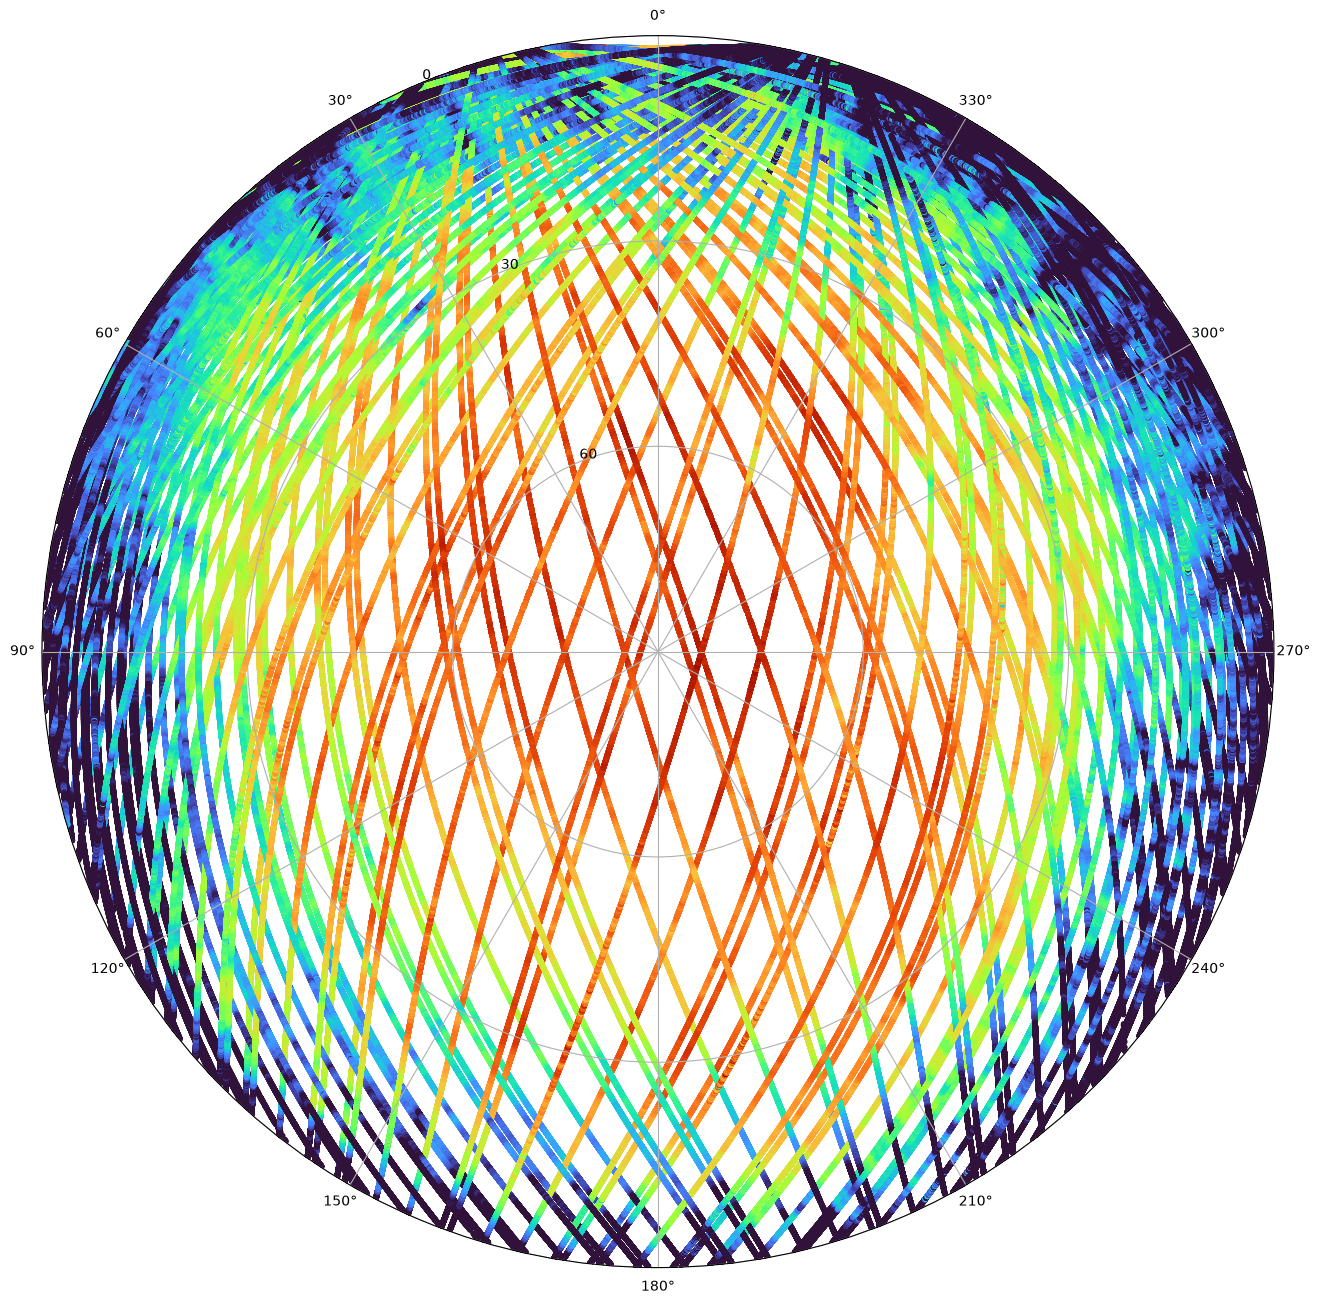

In [19]:
m2_3_obs = process_observations(target_id=57166)

0it [00:00, ?it/s]

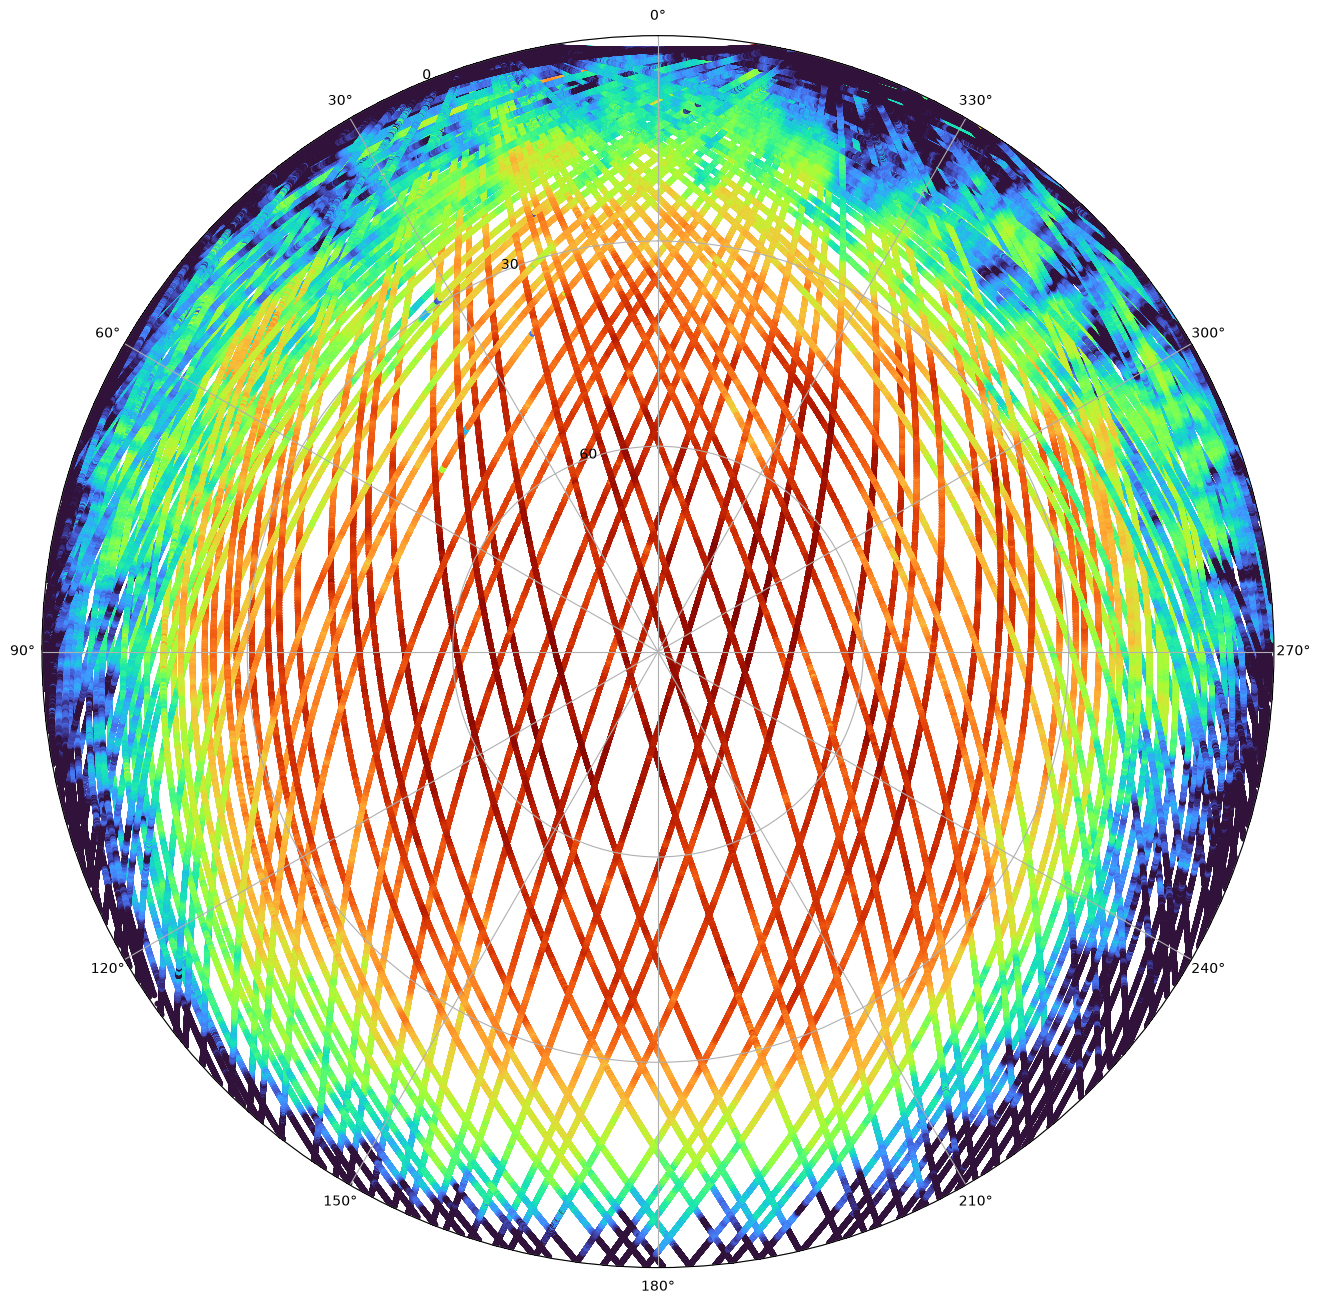

In [20]:
m2_4_obs = process_observations(target_id=59051)

In [21]:
# save the dataframes to CSV files
os.makedirs("dfs", exist_ok=True)
for i, df in enumerate(m2_3_obs):
    df.to_csv(f"dfs/m2_3_obs_{i}.csv", index=False)

for i, df in enumerate(m2_4_obs):
    df.to_csv(f"dfs/m2_4_obs_{i}.csv", index=False)